In [ ]:
# =====================================================================================
# CELL 1: Sign in to Earth Engine and open a map to draw the search rectangle.
#
# WHAT WE ARE LOOKING FOR
#   The landslide that blocked the Budhi Gandaki on 11 Oct 2026. We search for it inside
#   the rectangle you draw, comparing Sentinel-2 images from before the flood (1-6 Oct)
#   with the pass at 10:55 Nepal time on 11 Oct.
#
# WHAT THIS CELL DOES
#   Signs in, then loads three layers for you to look at while drawing:
#     - elevation (Copernicus GLO-30 DEM)
#     - slope (dark = steep), which later cells use to separate steep source slopes
#       from gentle deposit or flood ground
#     - Sentinel-2 true colour from 11 Oct, so you can see the river, both banks and
#       any bare patches
#   The rectangle you draw becomes the search area for every later cell.
#
# HOW IT IS USED LATER
#   Cell 2 reads the rectangle. Cells 3 onward only look inside it.
# =====================================================================================
import ee, geemap

ee.Authenticate()   # skip once you have authenticated on this machine
ee.Initialize()     # or ee.Initialize(project="your-gcp-project-id")

glo = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM")
dem = glo.mosaic().setDefaultProjection(glo.first().projection())
slope = ee.Terrain.slope(dem)

view = ee.Geometry.Rectangle([84.6, 28.1, 85.3, 28.8])      # wide box, only used to pick scenes for display
s2_post = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(view)
           .filterDate("2026-10-11", "2026-10-12").mosaic())

Map = geemap.Map(center=[28.46, 84.945], zoom=12)
Map.addLayer(s2_post, {"bands": ["B4", "B3", "B2"], "min": 200, "max": 3000}, "Sentinel-2, 11 Oct 2026 (true colour)")
Map.addLayer(slope, {"min": 0, "max": 60, "palette": ["#ffffff", "#bdbdbd", "#525252", "#000000"]}, "Slope (dark = steep)", False)
Map.addLayer(dem, {"min": 500, "max": 4500, "palette": ["#173b8f", "#239bd1", "#67bd63", "#f6e65c", "#e88232", "#f4f1e8"]}, "Elevation", False)
Map

# =====================================================================================


Wide area: 2912 km2
BEFORE scenes: 6 | AFTER scenes: 2


Map(center=[28.46, 84.945], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

In [ ]:
# =====================================================================================
# CELL 2 (updated): Overview map for finding the spot, then you draw the SMALL search box on it.
#
# WHAT WE ARE LOOKING FOR
#   Ground that was green before the flood and is bare after it. A landslide strips the
#   vegetation off a slope, and NDVI (a vegetation index, high on green plants and
#   near zero on bare soil or rock) drops sharply.
#
# WHAT THIS CELL DOES
#   1. Reads the wide rectangle from Cell 1 (called WIDE here, used only for the overview).
#   2. BEFORE = Sentinel-2 scenes from 1-10 Oct (last clear one is 6 Oct).
#      AFTER  = the 11 Oct 10:55 Nepal-time pass, after the flood.
#      Clouds, cloud shadow and cirrus are masked, and the newest clear pixel wins.
#   3. Computes NDVI change (after minus before) and a bare-soil index change, and loads
#      height above the nearest channel (HAND) for later.
#   4. Shows the map. YOU DRAW the small search rectangle on THIS map (map name: m2).
#
# CAUTION
#   The AFTER image was taken after the flood, so vegetation loss along the channel can be
#   flood scour or slurry. Cell 3 separates that from slope failure.
# =====================================================================================
import math

drawn = Map.user_rois
feats = drawn.getInfo()["features"] if drawn is not None else []
polys = [f for f in feats if f["geometry"]["type"] in ("Polygon", "MultiPolygon")]
if len(polys) != 1:
    raise ValueError(f"Cell 1's map needs exactly ONE rectangle. Found {len(polys)}.")
WIDE = ee.Geometry(polys[0]["geometry"])
print(f"Wide area: {WIDE.area(100).divide(1e6).getInfo():.0f} km2")

S2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(WIDE)

def mosaic(start, end):
    def prep(img):
        scl = img.select("SCL")
        ok = scl.neq(1).And(scl.neq(3)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
        return (img.select(["B2", "B3", "B4", "B8", "B11"]).divide(10000).updateMask(ok)
                .copyProperties(img, ["system:time_start"]))
    return S2.filterDate(start, end).map(prep).sort("system:time_start").mosaic()

pre, post = mosaic("2026-10-01", "2026-10-11"), mosaic("2026-10-11", "2026-10-12")
print("BEFORE scenes:", S2.filterDate("2026-10-01", "2026-10-11").size().getInfo(),
      "| AFTER scenes:", S2.filterDate("2026-10-11", "2026-10-12").size().getInfo())

ndvi = lambda im: im.normalizedDifference(["B8", "B4"])
d_ndvi = ndvi(post).subtract(ndvi(pre)).rename("d_ndvi")     # negative = vegetation lost
hand = ee.Image("MERIT/Hydro/v1_0_1").select("hnd").rename("hand")   # height above nearest drainage (m)

rgb = {"bands": ["B4", "B3", "B2"], "min": 0.02, "max": 0.30}
m2 = geemap.Map(center=[28.46, 84.945], zoom=13)
m2.addLayer(post, rgb, "AFTER true colour (11 Oct)")
m2.addLayer(pre, rgb, "BEFORE true colour (1-10 Oct)", False)
m2.addLayer(d_ndvi, {"min": -0.8, "max": 0.0, "palette": ["#000000", "#ffffff"]}, "NDVI change (BLACK = most vegetation lost)")
m2
# =====================================================================================


Wide area: 2912 km2
BEFORE scenes: 6 | AFTER scenes: 2


Map(center=[28.46, 84.945], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

In [ ]:
# =====================================================================================
# CELL 3: List the bare patches inside your small rectangle, on BOTH banks, with numbers.
#
# WHAT WE ARE LOOKING FOR
#   Whether the bare ground is (a) a steep slope failure, (b) a gentle, low deposit or
#   runout, or (c) flood scour, and whether the two banks are one event or two.
#
# WHAT THIS CELL DOES
#   1. Reads the rectangle you drew on the Cell 2 map (m2) as the search area (AOI).
#   2. Marks ground that lost vegetation (NDVI fell by more than 0.4) and is now bare
#      (NDVI below 0.3). No slope cut and no distance-to-river cut, so nothing on either
#      bank is filtered out for being gentle or near the water.
#   3. Prints the 15 biggest patches with: area, elevation range, mean slope, height above
#      the nearest channel (HAND), the direction the slope FACES, and the mean NDVI change.
#      "*" in the last column means the patch touches the rectangle edge, so its area is
#      cut off.
#   4. Prints a grid of changed area by slope class and by height above the channel.
#   5. Draws the patch outlines on the map.
# =====================================================================================
drawn = m2.user_rois
feats = drawn.getInfo()["features"] if drawn is not None else []
polys = [f for f in feats if f["geometry"]["type"] in ("Polygon", "MultiPolygon")]
if len(polys) != 1:
    raise ValueError(f"Draw exactly ONE rectangle on the Cell 2 map (m2), then rerun. Found {len(polys)}.")
AOI = ee.Geometry(polys[0]["geometry"])
print(f"Search area: {AOI.area(100).divide(1e6).getInfo():.1f} km2")

bare = d_ndvi.lt(-0.40).And(ndvi(post).lt(0.30)).selfMask()
bare = bare.updateMask(bare.connectedPixelCount(100, True).gte(15)).rename("bare")   # about 0.15 ha minimum

asp = ee.Terrain.aspect(dem).multiply(math.pi / 180)
terr = ee.Image.cat([dem.rename("elev"), slope.rename("slope"), hand,
                     asp.sin().rename("s"), asp.cos().rename("c")])
rd = ee.Reducer.min().combine(ee.Reducer.max(), sharedInputs=True).combine(ee.Reducer.mean(), sharedInputs=True)
inner = AOI.buffer(-40, 10)

vec = bare.reduceToVectors(geometry=AOI, scale=10, eightConnected=True, maxPixels=1e10, bestEffort=True)
vec = vec.map(lambda f: f.set("ha", f.geometry().area(10).divide(1e4))).sort("ha", False).limit(15)

def add(f):
    g = f.geometry(); c = g.centroid(10).coordinates()
    t = terr.reduceRegion(rd, g, 30, maxPixels=1e9, bestEffort=True)
    n = d_ndvi.reduceRegion(ee.Reducer.mean(), g, 10, maxPixels=1e9, bestEffort=True)
    return f.set({"lon": c.get(0), "lat": c.get(1),
                  "emin": t.get("elev_min"), "emax": t.get("elev_max"), "slope": t.get("slope_mean"),
                  "hand": t.get("hand_mean"), "s": t.get("s_mean"), "c": t.get("c_mean"),
                  "dn": n.get("d_ndvi"), "edge": g.difference(inner, 10).area(10).gt(100)})

def face(s, c):
    if s is None or c is None: return "--"
    deg = (math.degrees(math.atan2(s, c)) + 360) % 360
    return ["N", "NE", "E", "SE", "S", "SW", "W", "NW"][int((deg + 22.5) // 45) % 8]

rows = [f["properties"] for f in vec.map(add).getInfo()["features"]]
print(f"\n{'#':>3s}{'lat':>8s}{'lon':>9s}{'ha':>7s}{'elev min':>9s}{'elev max':>9s}{'drop m':>7s}"
      f"{'slope':>7s}{'HAND m':>8s}{'faces':>7s}{'dNDVI':>7s}  edge")
for i, r in enumerate(rows, 1):
    em, eM = r.get("emin") or 0, r.get("emax") or 0
    dn = r.get("dn")
    print(f"{i:3d}{r['lat']:8.4f}{r['lon']:9.4f}{r['ha']:7.1f}{em:9.0f}{eM:9.0f}{eM - em:7.0f}"
          f"{(r.get('slope') or 0):7.1f}{(r.get('hand') or 0):8.0f}{face(r.get('s'), r.get('c')):>7s}"
          f"{(dn if dn is not None else float('nan')):7.2f}  {'*' if r.get('edge') else ''}")

SL = {"<15 deg": (0, 15), "15-30": (15, 30), ">30": (30, 90)}
HL = {"<10 m": (0, 10), "10-50 m": (10, 50), ">50 m": (50, 99999)}
imgs, keys = [], []
for sl, (a, b) in SL.items():
    for hl, (c0, d0) in HL.items():
        cond = slope.gte(a).And(slope.lt(b)).And(hand.gte(c0)).And(hand.lt(d0))
        imgs.append(ee.Image.pixelArea().divide(1e4).updateMask(cond).updateMask(bare).rename(f"b{len(keys)}"))
        keys.append((sl, hl))
tot = ee.Image.cat(imgs).unmask(0).reduceRegion(ee.Reducer.sum(), AOI, 10, maxPixels=1e10, bestEffort=True).getInfo()
print("\nChanged (bare) area in ha: rows = slope, columns = height above the nearest channel")
print(f"{'':>10s}" + "".join(f"{h:>10s}" for h in HL))
for sl in SL:
    print(f"{sl:>10s}" + "".join(f"{tot.get('b' + str(keys.index((sl, h)))) or 0:10.1f}" for h in HL))

m3 = geemap.Map()
m3.centerObject(AOI, 14)
m3.addLayer(post, rgb, "AFTER true colour (11 Oct)")
m3.addLayer(pre, rgb, "BEFORE true colour (1-10 Oct)", False)
m3.addLayer(vec.style(color="ffffff", fillColor="00000000", width=2), {}, "Bare patches (white outline)")
m3.addLayer(AOI, {"color": "yellow"}, "Search rectangle", False)
m3
# =====================================================================================

#


Search area: 164.3 km2

  #     lat      lon     ha elev min elev max drop m  slope  HAND m  faces  dNDVI  edge
  1 28.4787  84.9355  652.5     1886     4210   2324   41.1     260     SE  -0.75  
  2 28.5036  84.9295   32.1     3180     3986    806   41.7     219     SW  -0.77  
  3 28.4340  85.0058   22.0     3972     4390    418   38.3     434      N  -0.64  
  4 28.4313  84.9992   17.8     4004     4368    364   33.4     157      N  -0.60  
  5 28.4216  84.9549   10.7     3586     4296    709   51.3     853     NW  -0.57  *
  6 28.5208  84.8861    9.7     3352     3810    458   45.4     528     NW  -0.54  *
  7 28.4220  84.9414    9.4     3337     3800    463   46.9     297     NW  -0.60  *
  8 28.4344  85.0092    8.9     3963     4276    313   27.8     273      N  -0.62  
  9 28.4395  84.9000    8.4     1626     2008    382   25.1       5      E  -0.71  
 10 28.5138  84.9014    8.4     4027     4408    381   46.5     393      W  -0.46  
 11 28.4374  84.9868    8.2     4049     4418

Map(center=[28.471573462420665, 84.94238100000236], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# =====================================================================================
# CELL 4: Separate the LOW ground (where the dam would be) from the ALPINE ground, and
# check both banks by the direction each slope faces.
#
# WHAT WE ARE LOOKING FOR
#   Bare ground on BOTH banks of the river at the same low elevation (the scar's range is
#   about 1,900-2,800 m). That is what a slope failure plus an opposite-bank deposit or a
#   second failure would look like. Bare ground only on high, north-facing slopes is more
#   likely snow, shadow or sun-angle effects.
#
# WHAT THIS CELL DOES
#   1. Takes the 3 km zone around the candidate (clipped to your rectangle).
#   2. Grid: changed (bare) area in ha by elevation band (rows) and by the direction the
#      slope faces (columns).
#   3. Lists the bare patches BELOW 2850 m, split apart (erode, then dilate, with
#      4-connectivity) so the two banks are no longer fused into one blob.
#   4. Map: yellow outlines = low patches, white fill = bare ground above 2850 m.
# =====================================================================================
Z = ee.Geometry.Point([84.9448, 28.4601]).buffer(3000).intersection(AOI, 10)

octant = ee.Terrain.aspect(dem).add(22.5).divide(45).floor().mod(8)
names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
EB = {"below 2850 m": (0, 2850), "2850-3500 m": (2850, 3500), "above 3500 m": (3500, 9000)}

imgs, keys = [], []
for en, (a, b) in EB.items():
    for k in range(8):
        cond = dem.gte(a).And(dem.lt(b)).And(octant.eq(k))
        imgs.append(ee.Image.pixelArea().divide(1e4).updateMask(cond).updateMask(bare).rename(f"b{len(keys)}"))
        keys.append((en, k))
tot = ee.Image.cat(imgs).unmask(0).reduceRegion(ee.Reducer.sum(), Z, 10, maxPixels=1e10, bestEffort=True).getInfo()
print("Changed (bare) area in ha, by elevation band (rows) and direction the slope faces (columns)")
print(f"{'':>14s}" + "".join(f"{n:>7s}" for n in names))
for en in EB:
    print(f"{en:>14s}" + "".join(f"{tot.get('b' + str(keys.index((en, k)))) or 0:7.1f}" for k in range(8)))

low = bare.updateMask(dem.lt(2850)).unmask(0)
low = low.focalMin(15, "circle", "meters").focalMax(15, "circle", "meters").selfMask().rename("low")
lv = low.reduceToVectors(geometry=Z, scale=10, eightConnected=False, maxPixels=1e10, bestEffort=True)
lv = (lv.map(lambda f: f.set("ha", f.geometry().area(10).divide(1e4)))
        .filter(ee.Filter.gt("ha", 0.5)).sort("ha", False).limit(12).map(add))   # add() is from Cell 3

rows = [f["properties"] for f in lv.getInfo()["features"]]
print(f"\nBare patches below 2850 m, split apart")
print(f"{'#':>3s}{'lat':>8s}{'lon':>9s}{'ha':>7s}{'elev min':>9s}{'elev max':>9s}{'drop m':>7s}"
      f"{'slope':>7s}{'HAND m':>8s}{'faces':>7s}{'dNDVI':>7s}  edge")
for i, r in enumerate(rows, 1):
    em, eM, dn = r.get("emin") or 0, r.get("emax") or 0, r.get("dn")
    print(f"{i:3d}{r['lat']:8.4f}{r['lon']:9.4f}{r['ha']:7.1f}{em:9.0f}{eM:9.0f}{eM - em:7.0f}"
          f"{(r.get('slope') or 0):7.1f}{(r.get('hand') or 0):8.0f}{face(r.get('s'), r.get('c')):>7s}"
          f"{(dn if dn is not None else float('nan')):7.2f}  {'*' if r.get('edge') else ''}")

m4 = geemap.Map()
m4.centerObject(Z, 14)
m4.addLayer(post, rgb, "AFTER true colour (11 Oct)")
m4.addLayer(pre, rgb, "BEFORE true colour (1-10 Oct)", False)
m4.addLayer(bare.updateMask(dem.gte(2850)), {"palette": ["#ffffff"]}, "Bare ground above 2850 m (white)", False)
m4.addLayer(lv.style(color="ffff00", fillColor="00000000", width=3), {}, "Low bare patches (yellow outline)")
m4
# =====================================================================================


Changed (bare) area in ha, by elevation band (rows) and direction the slope faces (columns)
                    N     NE      E     SE      S     SW      W     NW
  below 2850 m   27.8   14.6   65.8   63.8   29.6   28.5   36.6   52.8
   2850-3500 m    0.4    9.4   31.2    7.2    3.9   31.1   15.9    0.0
  above 3500 m    0.0    0.0    0.0    0.0    0.0    0.3    0.7    0.0

Bare patches below 2850 m, split apart
  #     lat      lon     ha elev min elev max drop m  slope  HAND m  faces  dNDVI  edge
  1 28.4704  84.9385  186.0     1988     2889    900   41.8     223     SE  -0.67  
  2 28.4599  84.9443  101.6     1886     2824    939   41.1     236     NW  -0.74  
  3 28.4671  84.9489   14.8     2009     2324    315   38.9      96      S  -0.59  
  4 28.4538  84.9351    4.3     1883     2054    171   26.0      34     SE  -0.71  
  5 28.4586  84.9373    2.0     2017     2197    180   53.4     132     SE  -0.52  
  6 28.4598  84.9350    1.0     2406     2577    171   48.7     575     SE  

Map(center=[28.460103077668293, 84.94480009707969], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# =====================================================================================
# CELL 5: Where does the bare ground START and END on each bank, by elevation?
#
# WHAT WE ARE LOOKING FOR
#   Evidence for the direction of the event. If material came down from the north bank, that
#   bank should show a bare track from high up down to the river, and the south bank should be
#   damaged only part-way up. If both banks are bare up to similar heights, two failures (or
#   something that hit both sides) is more likely.
#
# WHAT THIS CELL DOES
#   Splits the 3 km zone (Z, from Cell 4) into the two valley sides by the direction each slope
#   faces: S-facing slopes = north bank, N-facing slopes = south bank (valid because the river
#   runs roughly east-west here). Then, for every 200 m of elevation, it prints how many ha are
#   bare and what share of that band that is. No elevation cut-off is applied.
# =====================================================================================
aspect = ee.Terrain.aspect(dem)
north_bank = aspect.gte(90).And(aspect.lt(270)).And(slope.gt(10))        # S-facing slopes sit on the north bank
south_bank = aspect.lt(90).Or(aspect.gte(270)).And(slope.gt(10))         # N-facing slopes sit on the south bank

E0, STEP = 1800, 200
bands_def = [(E0 + i * STEP, E0 + (i + 1) * STEP) for i in range(13)]    # 1800 ... 4400 m
pa = ee.Image.pixelArea().divide(1e4)
imgs, keys = [], []
for (a, b) in bands_def:
    inband = dem.gte(a).And(dem.lt(b))
    for gname, grp in (("n", north_bank), ("s", south_bank)):
        imgs.append(pa.updateMask(inband).updateMask(grp).rename(f"t{len(keys)}")); keys.append((a, gname, "all"))
        imgs.append(pa.updateMask(inband).updateMask(grp).updateMask(bare).rename(f"t{len(keys)}")); keys.append((a, gname, "bare"))
res = ee.Image.cat(imgs).unmask(0).reduceRegion(ee.Reducer.sum(), Z, 10, maxPixels=1e10, bestEffort=True).getInfo()
val = lambda a, gname, kind: res.get(f"t{keys.index((a, gname, kind))}") or 0

print(f"{'elevation (m)':>16s} | {'NORTH bank (S-facing slopes)':>31s} | {'SOUTH bank (N-facing slopes)':>31s}")
print(f"{'':>16s} | {'bare ha':>14s}{'% of band':>13s}    | {'bare ha':>14s}{'% of band':>13s}")
for (a, b) in bands_def:
    row = f"{a:>8d}-{b:<7d} |"
    for gname in ("n", "s"):
        t, br = val(a, gname, "all"), val(a, gname, "bare")
        row += f"{br:15.1f}{(br / t * 100 if t > 0 else float('nan')):12.0f}%    |"
    print(row)
# =====================================================================================


   elevation (m) |    NORTH bank (S-facing slopes) |    SOUTH bank (N-facing slopes)
                 |        bare ha    % of band    |        bare ha    % of band
    1800-2000    |            4.6          12%    |           10.1          25%    |
    2000-2200    |           30.9          28%    |           40.6          34%    |
    2200-2400    |           31.6          16%    |           40.8          21%    |
    2400-2600    |           46.8          23%    |           25.6          12%    |
    2600-2800    |           51.9          27%    |           18.5          10%    |
    2800-3000    |           43.9          25%    |           11.9           7%    |
    3000-3200    |           26.9          15%    |           13.0           9%    |
    3200-3400    |           12.6           8%    |            1.8           1%    |
    3400-3600    |            3.0           3%    |            0.3           0%    |
    3600-3800    |            0.1           0%    |            0.0    

In [ ]:
# =====================================================================================
# CELL 6: Outline the affected slopes by hand. Landslide inventories are normally drawn this way.
#
# WHAT WE ARE LOOKING FOR
#   The outline of each slope that lost its vegetation, drawn by you, so every number and
#   export in Cell 7 refers to exactly the ground you consider affected.
#
# WHAT THIS CELL DOES
#   Opens a map with AFTER and BEFORE true colour, the NDVI change layer and the bare-ground
#   layer, centred on the zone. You draw the polygons on THIS map (map name: m6).
# =====================================================================================
m6 = geemap.Map()
m6.centerObject(Z, 14)
m6.addLayer(post, rgb, "AFTER true colour (11 Oct)")
m6.addLayer(pre, rgb, "BEFORE true colour (1-10 Oct)", False)
m6.addLayer(d_ndvi, {"min": -0.8, "max": 0.0, "palette": ["#000000", "#ffffff"]}, "NDVI change (BLACK = most vegetation lost)", False)
m6.addLayer(bare, {"palette": ["#ffff00"]}, "Bare ground (yellow)", False)
m6
# =====================================================================================

# =====================================================================================

Map(center=[28.460103077668293, 84.94480009707969], controls=(WidgetControl(options=['position', 'transparent_…


=== Polygon 1 (north to south) ===
  Area (ha)                                      7117.6
  Lowest elevation (m)                           1643
  Highest elevation (m)                          5480
  Elevation range (m)                            3838
  Mean slope (deg)                               39.5
  Max slope (deg)                                74.2
  Mean height above nearest channel (m)          463
  Share more than 50 m above channel (%)         91
  Mean direction the slope faces                 S
  NDVI on 1 Oct                                  0.62
  NDVI on 6 Oct                                  0.59
  NDVI on 11 Oct                                 0.41
  NDVI change 1 to 6 Oct (before the flood)      -0.06
  NDVI change 6 to 11 Oct (event)                -0.25
  Share of outline classed as bare (%)           11
  Clear pixels on 1 Oct (%)                      100
  Clear pixels on 6 Oct (%)                      72
  Clear pixels on 11 Oct (%)                     66


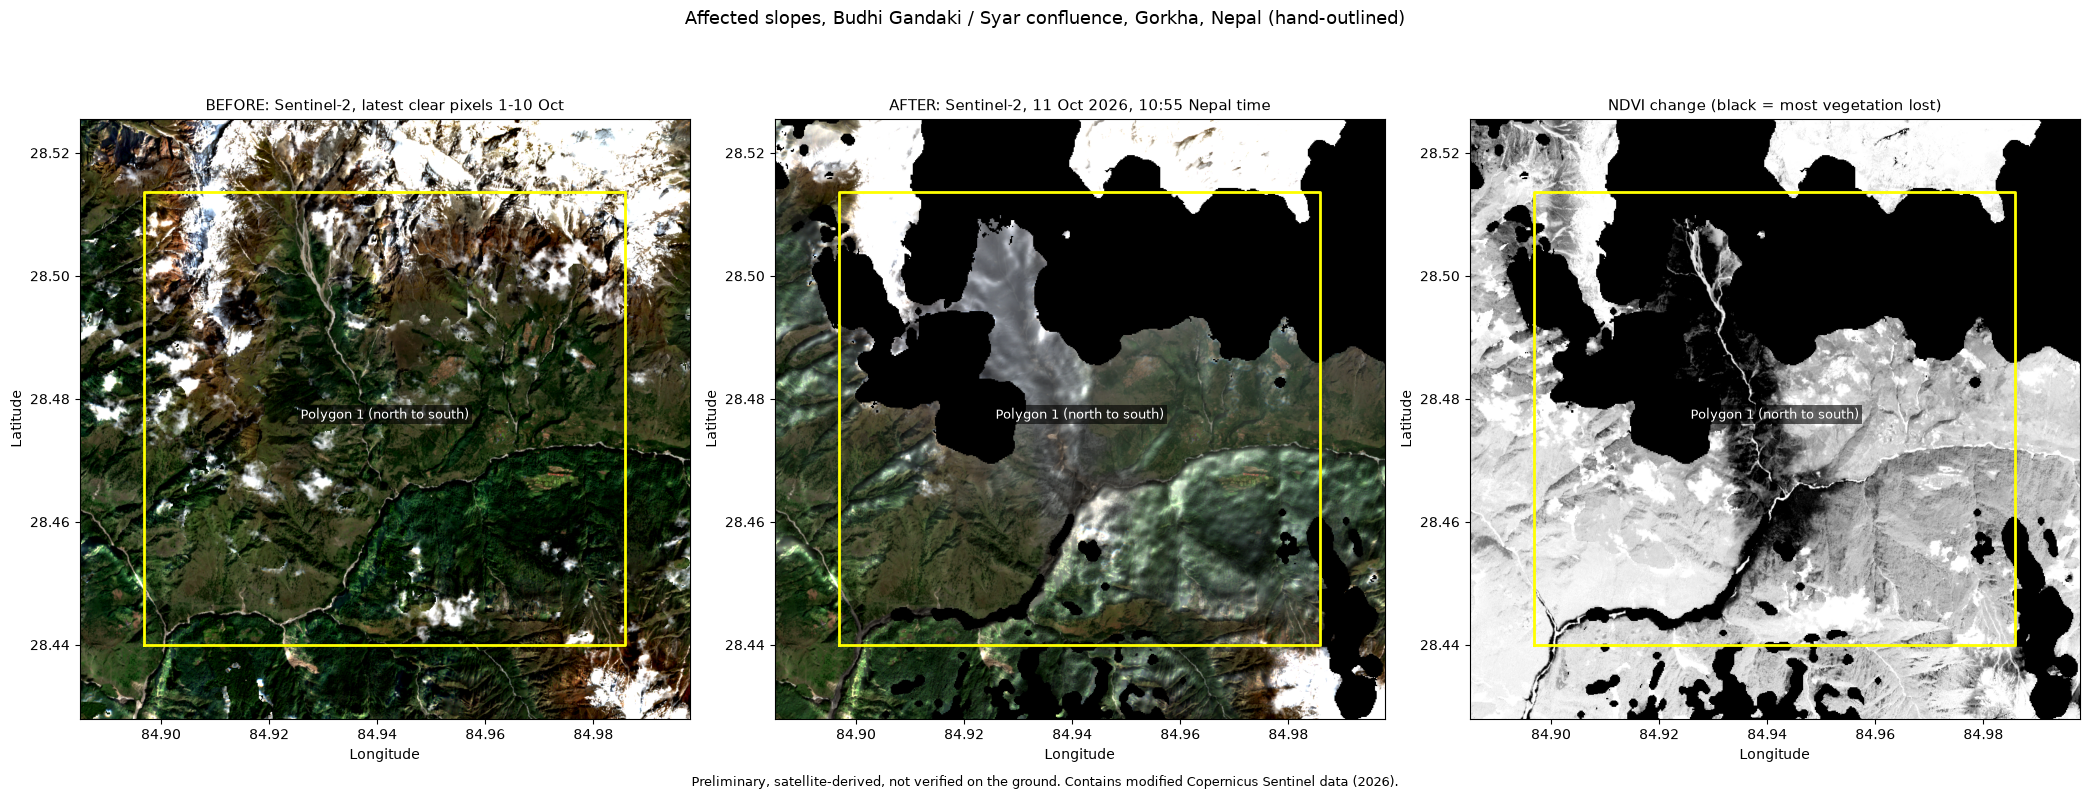


Saved in: D:\KGF\budigandaki\outputs
   affected_slopes.cpg
   affected_slopes.dbf
   affected_slopes.geojson
   affected_slopes.kml
   affected_slopes.prj
   affected_slopes.shp
   affected_slopes.shx
   affected_slopes_before_after.png
   affected_slopes_map.html
   sentinel2_before.png
   sentinel2_after.png
   ndvi_change.png



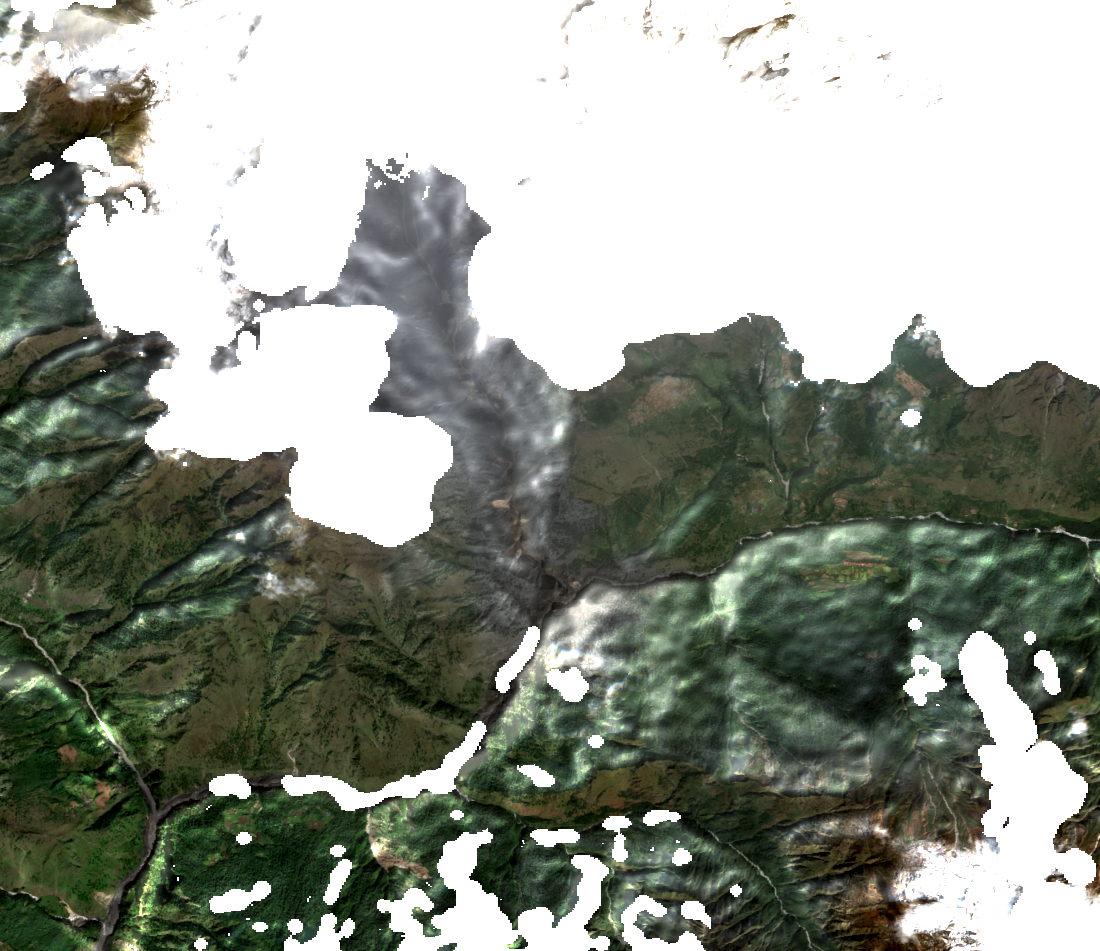
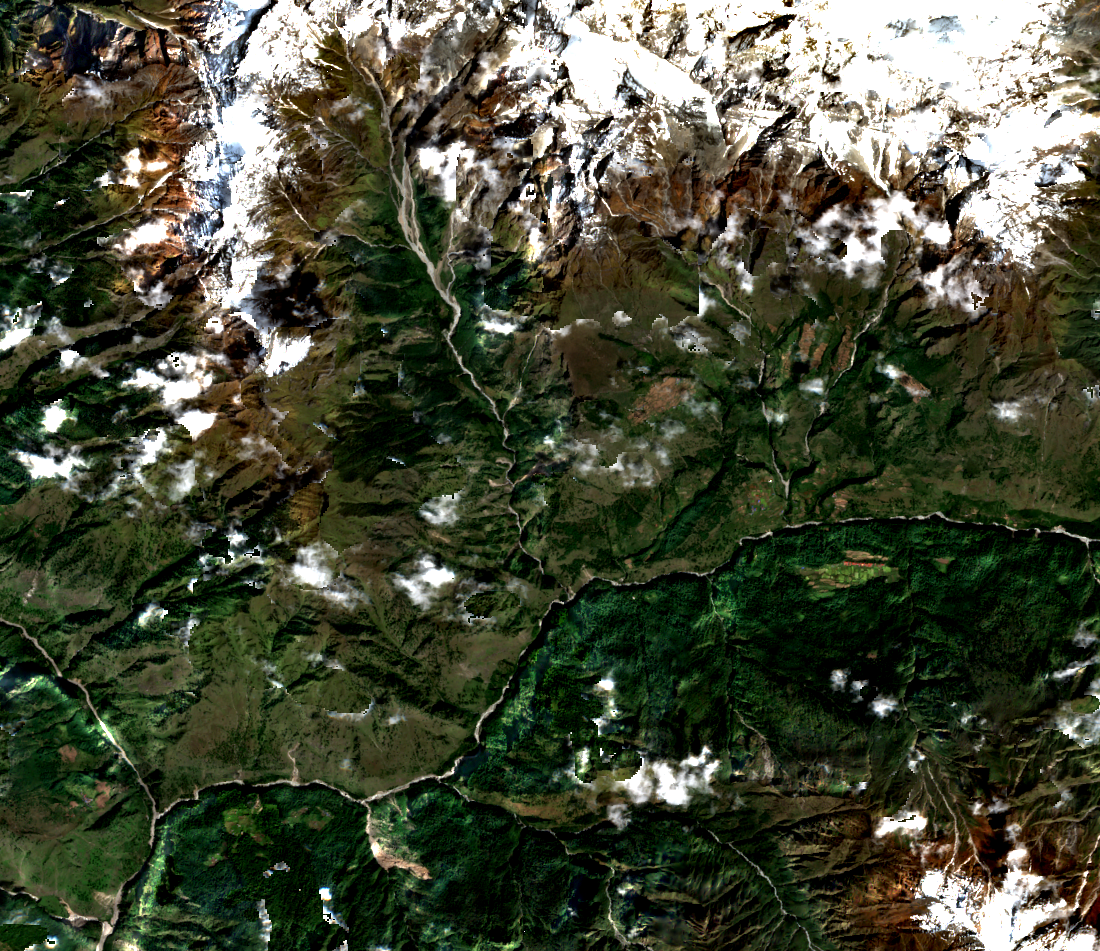
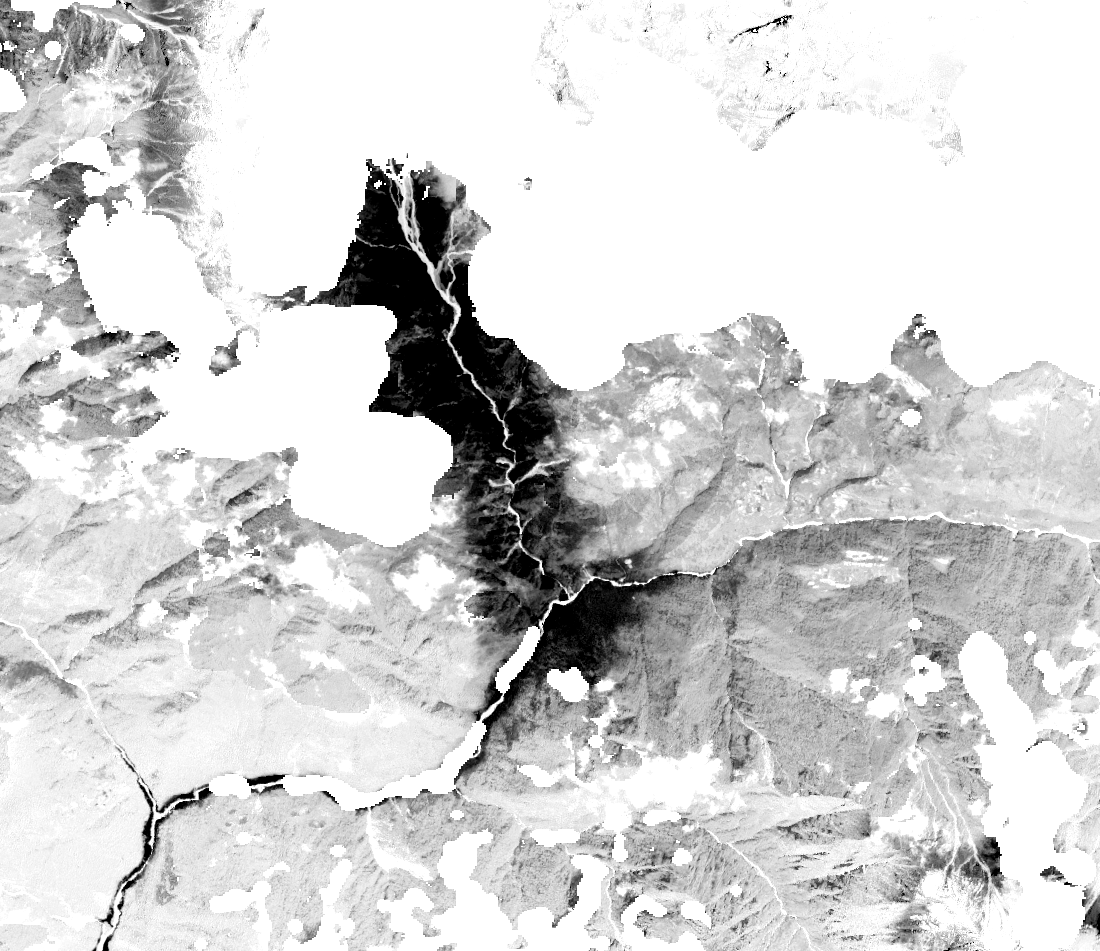

In [ ]:
# =====================================================================================
# CELL 7: Stats for each outline, plus every export.
#
# WHAT WE ARE LOOKING FOR
#   For each outlined slope: how big it is, how high, how steep, how far above the channel,
#   and how much its vegetation changed between 1 and 6 Oct (before the flood, a control) and
#   between 6 and 11 Oct (the event). A real event slope should be stable from 1 to 6 Oct and
#   drop from 6 to 11 Oct.
#
# WHAT THIS CELL DOES
#   1. Reads your polygons from m6, orders them north to south, and names them
#      ("North bank", "South bank" if you drew two; otherwise "Polygon 1, 2, ..."). To use your
#      own names, set NAMES = ["...", "..."] below, in order from north to south.
#   2. Prints the stats per polygon.
#   3. Saves in outputs/: GeoJSON, Shapefile, KML (with stats in each popup), a before/after
#      PNG with outlines, the three Sentinel-2 images, and a shareable OpenStreetMap HTML.
#   Needs: folium (pip install folium) and everything from Cells 1-4.
# =====================================================================================
import json, urllib.request
from pathlib import Path
from xml.sax.saxutils import escape
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import shape
from shapely.ops import unary_union

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
NAMES = None   # e.g. ["North bank", "South bank", "Western strip"] (north to south)

drawn = m6.user_rois
feats = drawn.getInfo()["features"] if drawn is not None else []
shapes = [f["geometry"] for f in feats if f["geometry"]["type"] in ("Polygon", "MultiPolygon")]
if not shapes:
    raise ValueError("No polygons found. Draw them on the Cell 6 map (m6), then rerun this cell.")
shapes.sort(key=lambda g: -shape(g).centroid.y)
if NAMES is None:
    NAMES = ["North bank", "South bank"] if len(shapes) == 2 else [f"Polygon {i + 1} (north to south)" for i in range(len(shapes))]
if len(NAMES) != len(shapes):
    raise ValueError(f"NAMES has {len(NAMES)} entries but you drew {len(shapes)} polygons.")

def day_ndvi(d):
    start = ee.Date(d)
    c = S2.filterDate(start, start.advance(1, "day"))
    def prep(img):
        scl = img.select("SCL")
        ok = scl.neq(1).And(scl.neq(3)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
        return img.select(["B8", "B4"]).divide(10000).normalizedDifference(["B8", "B4"]).rename("ndvi").updateMask(ok)
    return c.map(prep).mosaic()

n1, n6, n11 = day_ndvi("2026-10-01"), day_ndvi("2026-10-06"), day_ndvi("2026-10-11")
ndvi_stack = ee.Image.cat([n1.rename("n1"), n6.rename("n6"), n11.rename("n11"),
                           n6.subtract(n1).rename("d_1to6"), n11.subtract(n6).rename("d_6to11"),
                           n1.mask().rename("v1"), n6.mask().rename("v6"), n11.mask().rename("v11"),
                           bare.unmask(0).rename("bare")])

pct = lambda v: None if v is None else v * 100

def compute(gj):
    g = ee.Geometry(gj)
    t = terr.reduceRegion(rd, g, 30, maxPixels=1e9, bestEffort=True).getInfo()
    h = hand.gt(50).rename("hi").reduceRegion(ee.Reducer.mean(), g, 90, maxPixels=1e9, bestEffort=True).getInfo()
    n = ndvi_stack.reduceRegion(ee.Reducer.mean(), g, 10, maxPixels=1e10, bestEffort=True).getInfo()
    area = g.area(10).divide(1e4).getInfo()
    emin, emax = t.get("elev_min"), t.get("elev_max")
    return {"area_ha": area, "elev_min": emin, "elev_max": emax, "elev_mean": t.get("elev_mean"),
            "drop_m": None if emin is None or emax is None else emax - emin,
            "slope_mean": t.get("slope_mean"), "slope_max": t.get("slope_max"),
            "hand_mean": t.get("hand_mean"), "pct_above_50m": pct(h.get("hi")),
            "faces": face(t.get("s_mean"), t.get("c_mean")),
            "ndvi_1oct": n.get("n1"), "ndvi_6oct": n.get("n6"), "ndvi_11oct": n.get("n11"),
            "d_1to6": n.get("d_1to6"), "d_6to11": n.get("d_6to11"),
            "bare_pct": pct(n.get("bare")),
            "valid_1": pct(n.get("v1")), "valid_6": pct(n.get("v6")), "valid_11": pct(n.get("v11"))}

stats = [compute(g) for g in shapes]

LABELS = [("area_ha", "Area (ha)", "{:.1f}"), ("elev_min", "Lowest elevation (m)", "{:.0f}"),
          ("elev_max", "Highest elevation (m)", "{:.0f}"), ("drop_m", "Elevation range (m)", "{:.0f}"),
          ("slope_mean", "Mean slope (deg)", "{:.1f}"), ("slope_max", "Max slope (deg)", "{:.1f}"),
          ("hand_mean", "Mean height above nearest channel (m)", "{:.0f}"),
          ("pct_above_50m", "Share more than 50 m above channel (%)", "{:.0f}"),
          ("faces", "Mean direction the slope faces", "{}"),
          ("ndvi_1oct", "NDVI on 1 Oct", "{:.2f}"), ("ndvi_6oct", "NDVI on 6 Oct", "{:.2f}"),
          ("ndvi_11oct", "NDVI on 11 Oct", "{:.2f}"),
          ("d_1to6", "NDVI change 1 to 6 Oct (before the flood)", "{:+.2f}"),
          ("d_6to11", "NDVI change 6 to 11 Oct (event)", "{:+.2f}"),
          ("bare_pct", "Share of outline classed as bare (%)", "{:.0f}"),
          ("valid_1", "Clear pixels on 1 Oct (%)", "{:.0f}"), ("valid_6", "Clear pixels on 6 Oct (%)", "{:.0f}"),
          ("valid_11", "Clear pixels on 11 Oct (%)", "{:.0f}")]
f_ = lambda v, fm: "n/a" if v is None else fm.format(v)

for nm, s in zip(NAMES, stats):
    print(f"\n=== {nm} ===")
    for k, lab, fm in LABELS:
        print(f"  {lab:46s} {f_(s[k], fm)}")

# ---- GeoJSON and Shapefile ----
feat_list = []
for nm, gj, s in zip(NAMES, shapes, stats):
    props = {k: (None if s[k] is None else (round(s[k], 3) if not isinstance(s[k], str) else s[k])) for k in s}
    feat_list.append({"type": "Feature", "properties": {"name": nm, **props}, "geometry": gj})
(OUT / "affected_slopes.geojson").write_text(json.dumps({"type": "FeatureCollection", "features": feat_list}), encoding="utf-8")

SHP = {"area_ha": "area_ha", "elev_min": "elev_min", "elev_max": "elev_max", "drop_m": "drop_m",
       "slope_mean": "slope_avg", "slope_max": "slope_max", "hand_mean": "hand_avg", "pct_above_50m": "pct_hi50",
       "faces": "faces", "ndvi_1oct": "ndvi_1oct", "ndvi_6oct": "ndvi_6oct", "ndvi_11oct": "ndvi_11oct",
       "d_1to6": "d_1to6", "d_6to11": "d_6to11", "bare_pct": "bare_pct"}
rows = [{"name": nm, **{SHP[k]: s[k] for k in SHP}} for nm, s in zip(NAMES, stats)]
gpd.GeoDataFrame(rows, geometry=[shape(g) for g in shapes], crs="EPSG:4326").to_file(OUT / "affected_slopes.shp")

# ---- KML (opens in Google Earth; click an outline for its stats) ----
KML_COL = ["ff00ffff", "ffffffff", "ff0080ff", "ffffff00", "ff00ff00", "ffff00ff"]
ring_kml = lambda ring: " ".join(f"{x},{y},0" for x, y, *_ in ring)
def poly_kml(poly):
    s = f"<Polygon><outerBoundaryIs><LinearRing><coordinates>{ring_kml(poly[0])}</coordinates></LinearRing></outerBoundaryIs>"
    for hole in poly[1:]:
        s += f"<innerBoundaryIs><LinearRing><coordinates>{ring_kml(hole)}</coordinates></LinearRing></innerBoundaryIs>"
    return s + "</Polygon>"
polys_of = lambda gj: [gj["coordinates"]] if gj["type"] == "Polygon" else gj["coordinates"]

styles = "".join(f'<Style id="s{i}"><LineStyle><color>{KML_COL[i % 6]}</color><width>3</width></LineStyle>'
                 f'<PolyStyle><color>33{KML_COL[i % 6][2:]}</color></PolyStyle></Style>' for i in range(len(shapes)))
marks = ""
for i, (nm, gj, s) in enumerate(zip(NAMES, shapes, stats)):
    tbl = "".join(f"<tr><td>{lab}</td><td><b>{f_(s[k], fm)}</b></td></tr>" for k, lab, fm in LABELS)
    marks += (f"<Placemark><name>{escape(nm)}</name><description><![CDATA[<table>{tbl}</table>"
              f"<p>Preliminary, satellite-derived (Sentinel-2), hand-outlined, not verified on the ground.</p>]]></description>"
              f"<styleUrl>#s{i}</styleUrl><MultiGeometry>{''.join(poly_kml(p) for p in polys_of(gj))}</MultiGeometry></Placemark>")
kml = (f'<?xml version="1.0" encoding="UTF-8"?><kml xmlns="http://www.opengis.net/kml/2.2"><Document>'
       f'<name>Affected slopes, Budhi Gandaki (11 Oct 2026)</name>{styles}{marks}</Document></kml>')
(OUT / "affected_slopes.kml").write_text(kml, encoding="utf-8")

# ---- Sentinel-2 images and the before/after PNG ----
minx, miny, maxx, maxy = unary_union([shape(g) for g in shapes]).bounds
pad = 0.012
lon0, lat0, lon1, lat1 = minx - pad, miny - pad, maxx + pad, maxy + pad
bbox = ee.Geometry.Rectangle([lon0, lat0, lon1, lat1])

def thumb(img, name, width=1100):
    url = img.getThumbURL({"region": bbox, "dimensions": width, "format": "png", "crs": "EPSG:4326"})
    p = OUT / f"{name}.png"
    urllib.request.urlretrieve(url, p)
    return p

rgb_vis = {"bands": ["B4", "B3", "B2"], "min": 0.02, "max": 0.30, "gamma": 1.2}
p_before = thumb(pre.visualize(**rgb_vis), "sentinel2_before")
p_after = thumb(post.visualize(**rgb_vis), "sentinel2_after")
p_dndvi = thumb(d_ndvi.visualize(min=-0.8, max=0.0, palette=["000000", "ffffff"]), "ndvi_change")

fig, axs = plt.subplots(1, 3, figsize=(21, 8), facecolor="white")
panels = [(p_before, "BEFORE: Sentinel-2, latest clear pixels 1-10 Oct"),
          (p_after, "AFTER: Sentinel-2, 11 Oct 2026, 10:55 Nepal time"),
          (p_dndvi, "NDVI change (black = most vegetation lost)")]
for ax, (p, title) in zip(axs, panels):
    ax.set_facecolor("black")
    ax.imshow(plt.imread(p), extent=[lon0, lon1, lat0, lat1], aspect=1 / np.cos(np.radians((lat0 + lat1) / 2)))
    for nm, gj in zip(NAMES, shapes):
        for poly in polys_of(gj):
            ring = poly[0]
            ax.plot([q[0] for q in ring], [q[1] for q in ring], color="yellow", lw=2)
        c = shape(gj).centroid
        ax.text(c.x, c.y, nm, color="white", fontsize=9, ha="center",
                bbox=dict(facecolor="black", alpha=0.6, pad=2, edgecolor="none"))
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.ticklabel_format(useOffset=False)
fig.suptitle("Affected slopes, Budhi Gandaki / Syar confluence, Gorkha, Nepal (hand-outlined)", fontsize=13)
fig.text(0.5, 0.01, "Preliminary, satellite-derived, not verified on the ground. Contains modified Copernicus Sentinel data (2026).",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(OUT / "affected_slopes_before_after.png", dpi=200)
plt.show()

# ---- Shareable OpenStreetMap HTML (one file; images are embedded) ----
try:
    import folium
except ImportError:
    raise ImportError("Run: pip install folium   (then rerun this cell)")

HEX = ["#ffd400", "#ffffff", "#ff8000", "#00e5ff", "#00ff00", "#ff00ff"]
fm_ = folium.Map(location=[(lat0 + lat1) / 2, (lon0 + lon1) / 2], zoom_start=14, tiles="OpenStreetMap", control_scale=True)
folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri, Maxar, Earthstar Geographics", name="Esri satellite (alternative base map)", show=False).add_to(fm_)
ov_bounds = [[lat0, lon0], [lat1, lon1]]
for nm, p in [("Sentinel-2 AFTER (11 Oct)", p_after), ("Sentinel-2 BEFORE (1-10 Oct)", p_before),
              ("NDVI change (black = vegetation lost)", p_dndvi)]:
    folium.raster_layers.ImageOverlay(image=str(p), bounds=ov_bounds, name=nm, opacity=0.9, show=False).add_to(fm_)

for i, (nm, gj, s) in enumerate(zip(NAMES, shapes, stats)):
    tbl = "".join(f"<tr><td style='padding:1px 8px 1px 0;color:#444'>{lab}</td><td><b>{f_(s[k], fm)}</b></td></tr>"
                  for k, lab, fm in LABELS)
    popup = folium.Popup(f"<div style='font:12.5px sans-serif'><b>{escape(nm)}</b><table>{tbl}</table></div>", max_width=420)
    col = HEX[i % 6]
    folium.GeoJson({"type": "Feature", "properties": {}, "geometry": gj}, name=nm,
                   style_function=lambda ft, col=col: {"color": col, "weight": 4, "fillColor": col, "fillOpacity": 0.2},
                   tooltip=f"{nm} (click for details)", popup=popup).add_to(fm_)

head = "".join(f"<th style='padding:2px 6px;text-align:right'>{escape(nm)}</th>" for nm in NAMES)
body = "".join(f"<tr><td style='padding:1px 8px 1px 0;color:#444'>{lab}</td>"
               + "".join(f"<td style='text-align:right'><b>{f_(s[k], fm)}</b></td>" for s in stats) + "</tr>"
               for k, lab, fm in LABELS)
panel = f"""
<div style="position:fixed;top:12px;left:56px;z-index:9999;background:white;padding:10px 14px;border:2px solid #333;border-radius:6px;
font:12.5px/1.35 sans-serif;max-width:440px;max-height:85vh;overflow:auto;box-shadow:0 2px 8px rgba(0,0,0,.3)">
<div style="font-size:14px"><b>Affected slopes, Budhi Gandaki flood, 11 Oct 2026</b><br>Syar / Budhi Gandaki confluence, Gorkha, Nepal</div>
<table style="margin-top:6px"><tr><th></th>{head}</tr>{body}</table>
<div style="margin-top:6px;color:#555;font-size:11.5px">Hand-outlined, preliminary and satellite-derived (Sentinel-2). Not verified on the ground.
Contains modified Copernicus Sentinel data (2026). Base map &copy; OpenStreetMap contributors.</div></div>"""
fm_.get_root().html.add_child(folium.Element(panel))
folium.LayerControl(collapsed=False).add_to(fm_)
fm_.fit_bounds(ov_bounds)
fm_.save(str(OUT / "affected_slopes_map.html"))
print("\nSaved in:", OUT.resolve())
for p in sorted(OUT.glob("affected_slopes*")) + [p_before, p_after, p_dndvi]:
    print("  ", p.name)
fm_
# =====================================================================================

# =====================================================================================